# 6.10 - What companies write: text features from annual reports and current reports

Every US public company files an annual report (the **10-K**) with the SEC, and a **current report** (the **8-K**)
whenever something material happens - results, an executive leaving, an acquisition, a restatement. Notebooks 6.2-6.9
used prices and accounts only. This one asks whether the *words* add anything: *Machine Learning for Trading*
(chapter 10) builds features from text, and three findings from the academic literature are tested here on the
S&P 1500, 2005-2024:

1. **Tone** - Loughran and McDonald (2011) built a dictionary of words that are negative, uncertain, litigious and
   so on *in a financial sense* (general-purpose dictionaries call "liability" or "tax" negative; in a 10-K they are
   not). A higher share of negative words predicted lower returns around the filing.
2. **"Lazy Prices"** - Cohen, Malloy and Nguyen (2020): most companies copy last year's 10-K with small edits. Those
   that change it substantially - less similar to the year before - did worse over the following year, and the market
   was slow to notice.
3. **Events** - an 8-K's item codes say what happened; some events (an executive leaving, a restatement) may carry
   news that prices absorb slowly.

A language model, **FinBERT** (a BERT model trained on financial text), scores the tone of sentences sampled from
each report's management's discussion (MD&A), as a second opinion on the dictionary.

The data: every 10-K and 8-K the companies filed since 2003 (`eqr load-sec-text`), with the instant EDGAR accepted
each - a feature on a month end uses only filings public before it.

In [1]:
import pandas as pd
from IPython.display import display

from equity_research import charts
from equity_research.research import causal as cz
from equity_research.research import evaluation as ev
from equity_research.research import labels as lb
from equity_research.research import linear as ln
from equity_research.research import store
from equity_research.research import text_features as tf
from equity_research.research import validation as va
from equity_research.research.cache import ResearchCache
from equity_research.research.data import load_universe_data
from equity_research.research.features import stack, unstack

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
charts.style()

UNIVERSE, START, END = "SP1500", "2005-01-01", "2024-12-31"  # END: the last day before the hold-out
FDR = 0.10
cache = ResearchCache()
SNAPSHOT = store.data_snapshot(cache)
TEXT_SNAPSHOT = store.data_snapshot(cache, tables=sorted(store.SEPARATE_TABLES))
assert TEXT_SNAPSHOT is not None, "run eqr load-sec-text, then eqr sync-cache"
BOTH = f"{SNAPSHOT} | text {TEXT_SNAPSHOT}"  # text artifacts depend on both data versions
data = load_universe_data(cache, UNIVERSE, START, END)
dates = data.rebalances
FEATURES = {"universe": UNIVERSE, "start": START, "end": END, "dates": "month ends", "version": 1}
long = store.load("features", "company_month_end", FEATURES, snapshot=SNAPSHOT)
assert long is not None, "run notebook 6.2 first: it builds the price and accounts features"
monthly = store.cached(
    "labels",
    "fwd_ret_month",
    {"universe": UNIVERSE, "start": START, "end": END, "dates": "rebalances"},
    lambda: lb.period_returns(data.returns, dates),
    snapshot=SNAPSHOT,
)
listings = cache.query("SELECT listing_id, issuer_id FROM ref.listing WHERE issuer_id IS NOT NULL")


def build_text() -> pd.DataFrame:
    """The text features of every member on every month end, from the reports and 8-Ks known then."""
    per_report = tf.report_features(tf.read_measures(cache))
    panels = tf.as_of(per_report, dates, listings) | tf.event_panels(tf.read_documents(cache), dates, listings)
    return stack(panels, data.members)


text_long = store.cached("features", "text_month_end", FEATURES | {"text": 1}, build_text, snapshot=BOTH)
text_panels = unstack(text_long)
reports = cache.query(
    "SELECT COUNT(DISTINCT filing_ref) AS reports, COUNT(DISTINCT issuer_id) AS companies FROM fund.text_measure"
)
documents = cache.query("SELECT form, COUNT(*) AS n FROM fund.document GROUP BY form ORDER BY n DESC")
print(f"{int(reports.loc[0, 'reports']):,} annual reports measured, of {int(reports.loc[0, 'companies']):,} companies")
display(documents.set_index("form").T)
print(f"{len(text_panels)} text features on {len(text_long):,} member-months")

left out 887 facts of 2 companies in ['GBP']


47,499 annual reports measured, of 3,015 companies


form,8-K,10-Q,10-K,8-K/A,10-K/A,10-Q/A,10-KT,10-KT/A
n,613332,142933,47490,15663,5772,4272,81,13


33 text features on 360,228 member-months


## Step 1 - coverage: how much of the index each feature reaches

The share of index members with a value, by year. The whole report is measured for nearly every company; a section
only when the 10-K contains it (banks and some others put their MD&A in an exhibit, and risk factors became
compulsory with the 2005 annual reports); a similarity only when there was a report a year before; FinBERT only where
the MD&A had prose sentences.

In [2]:
SHOWN = [
    "txt_negative",
    "txt_mdna_negative",
    "txt_risk_negative",
    "txt_sim_all",
    "txt_sim_risk",
    "txt_finbert_tone",
    "ev_8k_count",
]
year = text_long.index.get_level_values("date").year
coverage = text_long[SHOWN].notna().groupby(year).mean()
display(coverage.iloc[::3].style.format("{:.0%}"))

,txt_negative,txt_mdna_negative,txt_risk_negative,txt_sim_all,txt_sim_risk,txt_finbert_tone,ev_8k_count
date,,,,,,,
2005,91%,73%,0%,90%,0%,87%,92%
2008,93%,81%,88%,92%,85%,91%,94%
2011,95%,85%,90%,95%,89%,92%,95%
2014,95%,87%,91%,94%,89%,92%,96%
2017,96%,86%,88%,95%,85%,90%,96%
2020,97%,90%,90%,96%,86%,93%,98%
2023,98%,91%,86%,97%,84%,93%,98%


## Step 2 - what the text looks like over time

The median member's share of negative and uncertain words, and the median similarity of its report to the year
before. A rising negative share in 2008-2009 and 2020 would be the dictionary seeing the crises.

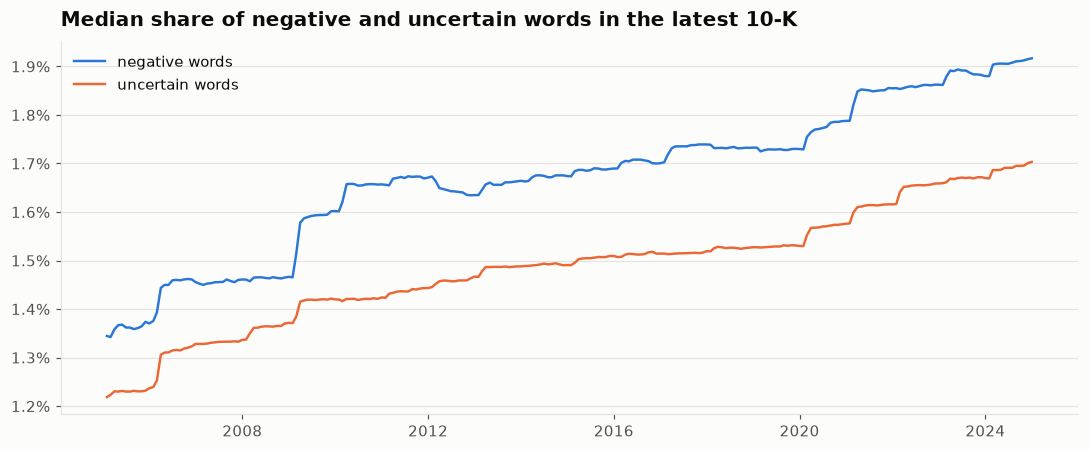

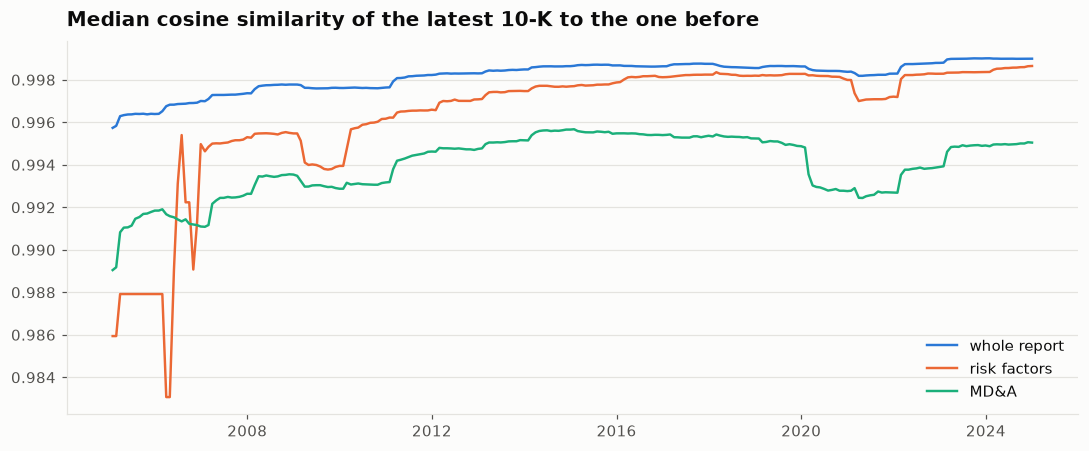

In [3]:
by_date = text_long.groupby(level="date")
fig = charts.lines(
    {"negative words": by_date["txt_negative"].median(), "uncertain words": by_date["txt_uncertainty"].median()},
    "Median share of negative and uncertain words in the latest 10-K",
    percent=True,
    decimals=1,
)
fig = charts.lines(
    {
        "whole report": by_date["txt_sim_all"].median(),
        "risk factors": by_date["txt_sim_risk"].median(),
        "MD&A": by_date["txt_sim_mdna"].median(),
    },
    "Median cosine similarity of the latest 10-K to the one before",
)

## Step 3 - triage: does any text feature rank next month's returns?

The same test as notebook 6.2: each month end, the rank correlation (IC) between a feature and the next month's
return across members, averaged over 2005-2024 with a Newey-West t-statistic, then the Benjamini-Hochberg control of
false discoveries at 10 % across all the text features. Similarity is expected *positive* (non-changers do better),
negative tone *negative*.

,mean_ic,t_nw,p_value,discovery,spread,turnover,rank_autocorrelation
signal,,,,,,,
ev_acquisition,-0.0099,-5.54,0.0000,True,+nan%,30%,0.69
txt_risk_negative,+0.0129,+3.15,0.0016,True,+0.27%,4%,0.99
txt_risk_uncertainty,+0.0103,+2.89,0.0038,True,+0.02%,3%,0.99
txt_strong_modal,-0.0105,-2.85,0.0044,True,-0.13%,4%,0.99
txt_mdna_uncertainty,+0.0079,+2.83,0.0046,True,+0.10%,3%,0.99
ev_agreement,-0.0075,-2.81,0.0049,True,+0.43%,27%,0.69
ev_restructuring,+0.0054,+2.70,0.0069,True,+nan%,30%,0.69
txt_jaccard_all,+0.0078,+2.61,0.0090,True,+0.07%,6%,0.95
ev_8k_count,-0.0068,-2.46,0.0139,True,-0.17%,32%,0.75


12 of 33 text features are discoveries at a 10% false-discovery rate: ['ev_acquisition', 'txt_risk_negative', 'txt_risk_uncertainty', 'txt_strong_modal', 'txt_mdna_uncertainty', 'ev_agreement', 'ev_restructuring', 'txt_jaccard_all', 'ev_8k_count', 'txt_constraining', 'txt_d_risk_log_words', 'ev_restatement']; near misses (|t| >= 2): ['txt_d_log_words']


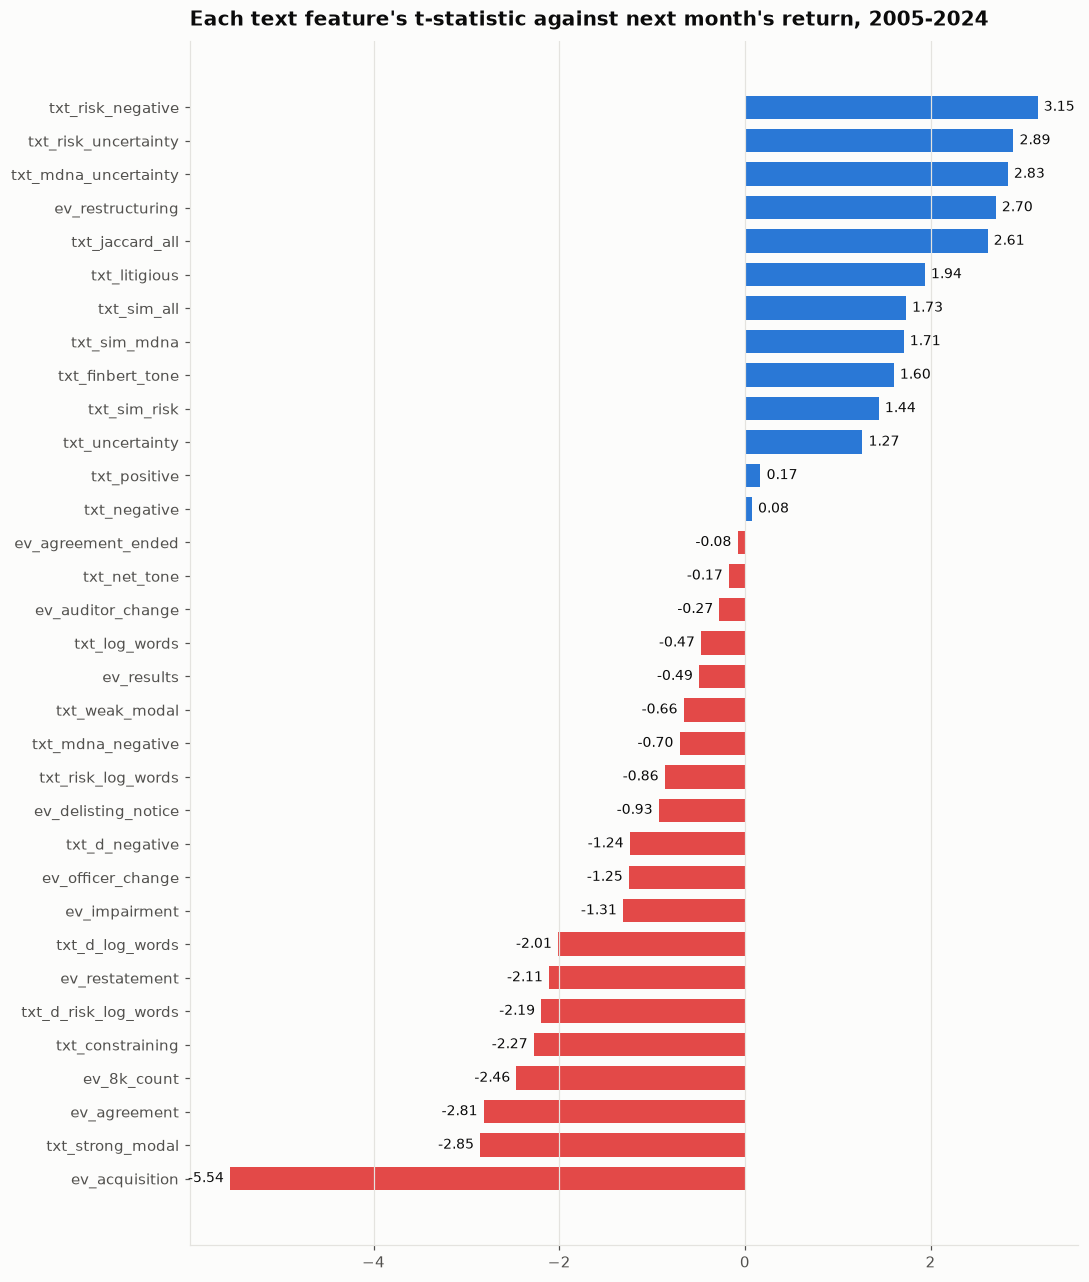

In [4]:
ledger = store.cached(
    "triage",
    "text_features_month",
    FEATURES | {"text": 1, "label": "fwd_ret_month", "fdr": FDR},
    lambda: ev.triage(text_panels, monthly, data.members, lags=0, q=FDR),
    snapshot=BOTH,
)
display(
    ledger.style.format(
        {
            "mean_ic": "{:+.4f}",
            "t_nw": "{:+.2f}",
            "p_value": "{:.4f}",
            "spread": "{:+.2%}",
            "turnover": "{:.0%}",
            "rank_autocorrelation": "{:.2f}",
        }
    )
)
discoveries = list(ledger.index[ledger["discovery"]])
near = list(ledger.index[~ledger["discovery"] & (ledger["t_nw"].abs() >= 1.99)])
print(
    f"{len(discoveries)} of {len(ledger)} text features are discoveries at a {FDR:.0%} false-discovery rate: "
    f"{discoveries}; near misses (|t| >= 2): {near}"
)
fig = charts.ranked_bars(ledger["t_nw"], "Each text feature's t-statistic against next month's return, 2005-2024")

## Step 4 - "Lazy Prices": the returns of changers and non-changers

Members sorted each month end into fifths by the similarity of their latest 10-K to the one before (fifth 1: the
biggest changers), the mean next-month return of each fifth, and the top-minus-bottom spread with its t-statistic.
Cohen, Malloy and Nguyen found non-changers beating changers by 30-60 basis points a month in a broader sample.

In [5]:
rows = {}
for name in ["txt_sim_all", "txt_jaccard_all", "txt_sim_mdna", "txt_sim_risk"]:
    table = ev.quantile_returns(text_panels[name], monthly, data.members, quantiles=5)
    spread = ev.quantile_spread(table).dropna()
    rows[name] = {
        **{f"fifth {q}": table[q].mean() for q in table.columns},
        "spread": spread.mean(),
        "t": ev.newey_west_t(spread, 0),
        "months": len(spread),
    }
display(
    pd.DataFrame(rows).T.style.format(
        {**{f"fifth {q}": "{:+.2%}" for q in range(1, 6)}, "spread": "{:+.2%}", "t": "{:+.2f}", "months": "{:.0f}"}
    )
)

,fifth 1,fifth 2,fifth 3,fifth 4,fifth 5,spread,t,months
txt_sim_all,+1.03%,+0.96%,+0.99%,+0.95%,+1.00%,-0.03%,-0.34,239
txt_jaccard_all,+0.96%,+0.94%,+1.03%,+0.97%,+1.03%,+0.07%,+0.81,239
txt_sim_mdna,+1.07%,+0.96%,+1.00%,+0.92%,+1.01%,-0.06%,-0.65,239
txt_sim_risk,+0.90%,+0.99%,+1.14%,+0.95%,+0.97%,+0.07%,+0.82,216


## Step 5 - is the text new information, or the same as prices and accounts?

A text feature can rank companies well only because it repeats something already measured - a volatile company's
10-K is full of risk words. First the rank correlation of each promising text feature (the discoveries and near
misses of step 3) with its closest features from notebook 6.2; then the factor zoo of notebook 6.9: each one as the
"treatment" in a double-ML regression with *all* the other features - the 45 of 6.2 and the other text features -
as flexibly fitted controls. One that keeps an effect adds something of its own.

In [6]:
promising = discoveries + near
if promising:
    base = unstack(long)
    corr = ev.rank_correlations({n: text_panels[n] for n in promising}, base, data.members)
    closest = {n: corr.loc[n].abs().sort_values(ascending=False).head(3) for n in promising}
    display(
        pd.DataFrame(
            {n: {f"{i + 1}": f"{k} ({corr.loc[n, k]:+.2f})" for i, k in enumerate(c.index)} for n, c in closest.items()}
        ).T
    )
else:
    print("no text feature reached |t| >= 2: nothing to compare")

,1,2,3
ev_acquisition,share_change (+0.07),ROCE (-0.04),idio_vol_3m (+0.04)
txt_risk_negative,Op. In./Interest Expense (+0.22),Debt Ratio (-0.22),Asset Turnover (+0.20)
txt_risk_uncertainty,RE/TA (+0.16),Debt Ratio (-0.14),Op. In./Interest Expense (+0.13)
txt_strong_modal,size (-0.22),Gross Profit Margin (+0.21),Cash Ratio (+0.21)
txt_mdna_uncertainty,size (+0.09),amihud_1m (-0.09),dollar_volume_1m (+0.09)
ev_agreement,Debt Ratio (+0.11),Op. In./Interest Expense (-0.11),turnover_1m (+0.10)
ev_restructuring,Op. In./(NWC+FA) (-0.06),mom_12_1 (-0.06),EBIT/TA (-0.05)
txt_jaccard_all,Op. In./Interest Expense (+0.14),ROCE (+0.13),EBIT/TA (+0.11)
ev_8k_count,Book Equity/TL (-0.18),(CA-CL)/TA (-0.17),Working Capital Ratio (-0.15)
txt_constraining,RE/TA (-0.27),EBIT/TA (-0.25),Op. In./Interest Expense (-0.25)


In [7]:
combined = long.join(text_long, how="left")
x = ln.centred_ranks(combined)
y = lb.trimmed_excess(monthly, data.members)
labelled = dates[dates < dates[-1]]
ends = va.next_date_ends(dates)
blocks = va.purged_kfold(labelled, ends, k=5, embargo=1)
if promising:
    zoo = store.cached(
        "causal",
        "text_factor_zoo",
        FEATURES | {"text": 1, "candidates": promising, "k": 5, "fdr": FDR},
        lambda: cz.factor_zoo(x, y, promising, blocks, q=FDR),
        snapshot=BOTH,
    )
    zoo["alone (step 3)"] = ledger.loc[zoo.index, "mean_ic"]
    zoo["alone t"] = ledger.loc[zoo.index, "t_nw"]
    display(
        zoo.sort_values("t", key=abs, ascending=False).style.format(
            {
                "theta": "{:+.4f}",
                "se": "{:.4f}",
                "t": "{:+.2f}",
                "p_value": "{:.4f}",
                "rows": "{:,.0f}",
                "alone (step 3)": "{:+.4f}",
                "alone t": "{:+.2f}",
            }
        )
    )

,theta,se,t,p_value,rows,discovery,alone (step 3),alone t
characteristic,,,,,,,,
ev_acquisition,-0.0063,0.0018,-3.51,0.0004,"358,647",True,-0.0099,-5.54
txt_risk_negative,+0.0022,0.0011,+2.04,0.0418,"358,647",False,+0.0129,+3.15
txt_strong_modal,-0.0017,0.0010,-1.76,0.0783,"358,647",False,-0.0105,-2.85
txt_jaccard_all,+0.0016,0.0010,+1.61,0.1066,"358,647",False,+0.0078,+2.61
ev_restructuring,+0.0043,0.0030,+1.45,0.1464,"358,647",False,+0.0054,+2.70
txt_d_risk_log_words,-0.0009,0.0008,-1.08,0.2822,"358,647",False,-0.0056,-2.19
ev_8k_count,-0.0005,0.0009,-0.61,0.5449,"358,647",False,-0.0068,-2.46
ev_agreement,-0.0006,0.0011,-0.53,0.5989,"358,647",False,-0.0075,-2.81
ev_restatement,-0.0029,0.0056,-0.52,0.6009,"358,647",False,-0.0043,-2.11


## Step 6 - how large is the one that survives?

An IC says how well a feature *ranks* stocks, not how much money the ranking is worth. An event count is zero for
most members, so it cannot be cut into fifths as in step 4; instead, each month end, the mean next-month return of
the members with the event in the quarter before, less that of the members without - over the whole period and each
half, with a Newey-West t-statistic. Item 2.01 is the completion of an acquisition *or a disposal* of assets.

In [8]:
survivors = list(zoo.index[zoo["discovery"]]) if promising else []
rows = {}
for name in survivors:
    gap = tf.event_gap(text_panels[name], monthly, data.members) if name.startswith("ev_") else None
    if gap is None:
        continue
    with_event = (text_panels[name] > 0).where(data.members.reindex_like(text_panels[name]).fillna(False).astype(bool))
    for label, part in [
        ("2005-2024", gap),
        ("2005-2014", gap[gap.index.year <= 2014]),
        ("2015-2024", gap[gap.index.year >= 2015]),
    ]:
        rows[(name, label)] = {
            "members with the event (median)": with_event.sum(axis=1).median(),
            "gap a month": part.mean(),
            "gap a year": part.mean() * 12,
            "t": ev.newey_west_t(part, 0),
            "months": len(part),
        }
if rows:
    display(
        pd.DataFrame(rows).T.style.format(
            {
                "members with the event (median)": "{:.0f}",
                "gap a month": "{:+.2%}",
                "gap a year": "{:+.1%}",
                "t": "{:+.2f}",
                "months": "{:.0f}",
            }
        )
    )
else:
    print("no event feature keeps an effect of its own")

## Findings

*Run on 13 November 2026 on the rebuilt database (prices and accounts 2026-11-13, text 2026-11-13), FinBERT's tone
included.*

**In short: the words of annual reports add almost nothing that prices and accounts do not already say; one 8-K
event does.** Twelve of 33 text features rank next month's returns at a 10 % false-discovery rate, but with the 45
features of notebook 6.2 controlled for, only one keeps an effect of its own: a company that completed an
acquisition or a disposal (8-K item 2.01) in the quarter before. Those companies trailed the rest by 0.36 % a month
(4.4 % a year, t -3.9), in both halves of the period. Neither "Lazy Prices", nor the dictionary's tone, nor FinBERT's
tone repeats here.

**1. The data (setup, step 1).** 47,499 annual reports of 3,015 companies are measured, with 613,332 8-Ks (and
142,933 10-Qs, kept for later) giving the events: 33 features on 360,228 member-months. The whole report reaches
91-98 % of members each year, the MD&A 73-91 % (some companies put it in an exhibit), the year-on-year similarity
90-97 %, FinBERT's tone of the MD&A 87-93 %. Risk factors start with the 2005 annual reports, filed in 2006, and reach
86-91 % from 2008.

**2. The text over time (step 2).** Reports have grown more cautious: the median member's share of negative words
rose from about 1.35 % of words in January 2005 to 1.92 % in December 2024, of uncertain words from 1.22 % to 1.70 %.
The rise comes in steps each spring, when most 10-Ks are filed: the largest after the 2008 crisis (1.47 % in December
2008, 1.59 % by June 2009) and after the pandemic (1.73 % in December 2019, 1.85 % by June 2021); the step in 2006 is
when risk factors became compulsory. Companies also copy more of last year's report each year: the median cosine
similarity of the whole report rose from 0.9957 to 0.9990, of the risk factors from 0.995 (2008) to 0.999. Word-count
vectors are dominated by common words, so these values crowd near 1; what matters for ranking is which companies
sit lower. The MD&A changed most in the crisis years (its median dipped in 2009 and from 0.995 to 0.993 in 2020-21).

FinBERT reads the same crises in the MD&A's sentences. The median member's FinBERT tone (positive less negative
probability) is mildly positive most of the time - 0.037 in December 2019, 0.033 in December 2024 - but fell from
0.053 in December 2008 to 0.027 by June 2009, and from 0.037 to 0.022 in June 2020 and -0.004 by June 2021, the only
point where the typical MD&A leaned negative: the reports written about 2020. It agrees only loosely with the
dictionary (rank correlation 0.24 with net tone, -0.33 with the MD&A's share of negative words): a model reading
sentences and a word count measure tone differently.

**3. Triage (step 3).** Twelve features are discoveries; the strongest:

| Feature | IC | t | Reading |
|---|---|---|---|
| acquisition or disposal 8-K (count, last quarter) | -0.0099 | -5.54 | companies that just completed one do worse |
| negative words in risk factors | +0.0129 | +3.15 | the *opposite* sign of Loughran and McDonald's finding |
| uncertain words in risk factors / MD&A | +0.0103 / +0.0079 | +2.89 / +2.83 | |
| strong modal words ("will", "must") | -0.0105 | -2.85 | |
| material agreement 8-K | -0.0075 | -2.81 | |
| restructuring 8-K | +0.0054 | +2.70 | |
| Jaccard similarity of the whole report | +0.0078 | +2.61 | the "Lazy Prices" direction: copiers do better |

The whole report's tone does nothing: the negative share has an IC of +0.0003 (t +0.08), net tone -0.0008. **FinBERT's
tone points the expected way but is not a discovery**: IC +0.0057 (t +1.60) - companies whose MD&A reads more
positively did slightly better. The growth of the risk factors section since last year (-0.0056, t -2.19), the number
of 8-Ks (-0.0068, t -2.46) and restatements (-0.0043, t -2.11) are small discoveries; the change in length (t -2.01)
narrowly misses. For comparison, the plain composite of 6.2 has an IC of about 0.025.

**4. "Lazy Prices" does not repeat (step 4).** Sorted into fifths by similarity to last year's report, the biggest
changers and the biggest copiers earn the same next month: the spread is -0.03 % a month for the whole report's
cosine similarity (t -0.34), +0.07 % for its Jaccard similarity (t +0.81), -0.06 % for the MD&A and +0.07 % for the
risk factors - against the 30-60 basis points Cohen, Malloy and Nguyen found in a broader sample that includes smaller
companies. The Jaccard similarity's IC in step 3 ranks stocks a little, but not by enough to separate the fifths'
returns.

**5. Most text discoveries repeat prices and accounts (step 5).** The rank correlations show why: negative and
uncertain words in the risk factors go with safer balance sheets (higher interest cover +0.22 and +0.13, lower debt
-0.22 and -0.14), constraining words with weak profits (retained earnings / assets -0.27, EBIT / assets -0.25),
strong modal words with small companies (size -0.22), the Jaccard similarity with profitable ones (ROCE +0.13).
In the double-ML test with every other feature controlled for, only the acquisition-or-disposal count keeps an
effect: -0.0063 (t -3.51, a discovery). Negative risk words keep +0.0022 (t +2.04, p 0.04, not a discovery once the
13 tests are counted); every other one falls to |t| < 2.

**6. Its size (step 6).** In a typical month 66 members had completed an acquisition or disposal in the quarter
before. They trailed the other members by 0.36 % the next month (-4.4 % a year, t -3.91 over 239 months): -0.32 %
(t -2.71) in 2005-2014 and -0.41 % (t -2.84) in 2015-2024. This fits a long literature - acquirers do poorly after
their deals - but two cautions: 6.2's features include no measure of **asset growth**, a known effect of the same
kind (companies that grow their assets fast do worse), so part of this may be that; and item 2.01 mixes acquisitions
with disposals, which this run does not separate.

**7. What this means for the hold-out.** The text does not change the strategy candidates of 6.5-6.6, and FinBERT's
tone adds no discovery. The one new signal, the acquisition-or-disposal count, could be added to the composite - but
that is a new trial on 2005-2024, to be tested and counted (with asset growth as a control) *before* the 2025 hold-out
is opened, not after.

## Glossary

* **10-K / 8-K** - a US company's annual report / its report of a material event, filed with the SEC on EDGAR.
* **MD&A** - Item 7 of the 10-K, management's discussion and analysis of the year.
* **Risk factors** - Item 1A, the risks management lists; compulsory from the 2005 annual reports.
* **Loughran-McDonald dictionary** - word lists of negative, positive, uncertain, litigious, constraining and modal
  words, built for financial documents.
* **Cosine similarity** - the angle between two documents' word-count vectors: 1 when the words are used in the same
  proportions; **Jaccard similarity** - the share of the two vocabularies they have in common.
* **FinBERT** - a BERT language model fine-tuned to classify financial sentences as positive, negative or neutral.
* **IC / Newey-West t / Benjamini-Hochberg** - as in notebook 6.1: the monthly rank correlation of a feature with the
  next month's return, its t-statistic allowing for autocorrelation, and the control of false discoveries across many
  tests.
* **Double ML / factor zoo** - as in notebook 6.9: a feature's effect with every other feature controlled for
  flexibly.